# Choosing a threshold: why you should not tune on recall

A classifier that outputs probabilities needs a threshold to become a decision, and the threshold is often
chosen by maximising a measure on held-out data. Which measure you maximise decides where the threshold
ends up, and for some measures the answer is a trivial classifier. This notebook sweeps the threshold of a
cancer classifier, shows which measures have a maximum at an extreme, uses the closed-form optimum that the
library knows for some measures, and ends with a cost-weighted measure that has its own closed form.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from aggmetrics import IndicatorMatrix, diagnose, get_measure, register_measure

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## Data and probabilities

The Breast Cancer Wisconsin (Diagnostic) data, bundled with `scikit-learn`: 569 fine-needle aspirates described
by 30 features computed from digitised images (Street, Wolberg and Mangasarian, 1993; donated to the UCI
repository by Nick Street). The positive class is *malignant*: 212 cases, against 357 benign.

The probabilities come from a logistic regression, out of fold: each case is scored by a model that did not
see it, so that the sweep below is not flattered by the training data.

In [3]:
data = load_breast_cancer()
X = data.data
y = (data.target == 0).astype(int)              # 1 = malignant
print("cases:", len(y), "| malignant:", int(y.sum()), "| benign:", int((1 - y).sum()))

cv = StratifiedKFold(5, shuffle=True, random_state=0)
proba = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                          X, y, cv=cv, method="predict_proba")[:, 1]

def at(t):
    return IndicatorMatrix(y, (proba >= t).astype(int), task="binary")

im = at(0.5)
print("at the usual threshold of 0.5: accuracy", round(im.accuracy(), 3),
      "| recall", round(im.compute("recall", "micro"), 3),
      "| precision", round(im.compute("precision", "micro"), 3))

cases: 569 | malignant: 212 | benign: 357
at the usual threshold of 0.5: accuracy 0.979 | recall 0.958 | precision 0.985


## Sweeping the threshold

For every threshold between 0.001 and 0.999 the decisions are `proba >= t`, and each measure is computed on
them. The two panels separate the measures that move in one direction as the threshold rises from the ones
that have an interior optimum.

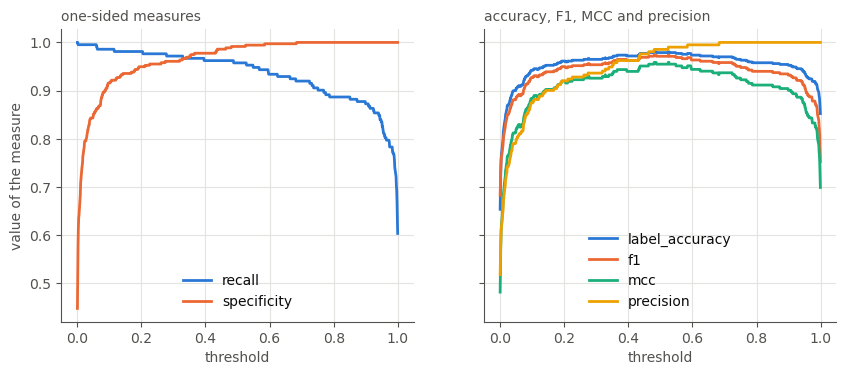

In [4]:
thresholds = np.linspace(0.001, 0.999, 999)
measures = ["label_accuracy", "recall", "specificity", "precision", "f1", "mcc",
            "balanced_accuracy", "kappa", "jaccard"]
curves = pd.DataFrame({m: [at(t).compute(m, "micro") for t in thresholds] for m in measures},
                      index=thresholds)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, cols, title in ((axes[0], [("recall", BLUE), ("specificity", ORANGE)], "one-sided measures"),
                        (axes[1], [("label_accuracy", BLUE), ("f1", ORANGE), ("mcc", AQUA), ("precision", YELLOW)],
                         "accuracy, F1, MCC and precision")):
    for name, color in cols:
        ax.plot(thresholds, curves[name], color=color, label=name)
    ax.set_xlabel("threshold")
    ax.set_title(title, loc="left", fontsize=10, color=INK2)
    ax.legend(frameon=False, loc="lower center")
axes[0].set_ylabel("value of the measure")
plt.show()

Recall falls and specificity rises as the threshold goes up, so each is maximised at one end. Accuracy, $F_1$
and MCC rise quickly, stay on a broad plateau through the middle and reach their maximum near 0.5.
Precision is the odd one: it is low at small thresholds, then reaches 1.0 and stays there.

The library stores, for the measures where one exists, the threshold on the conditional probability that
maximises the measure. Next to what the sweep finds:

In [5]:
def best_range(series):
    best = series.max()
    idx = series.index[series >= best - 1e-12]
    return best, idx.min(), idx.max()

rows = []
for m in measures:
    best, lo, hi = best_range(curves[m])
    closed_form = get_measure(m).bayes_threshold()
    rows.append(dict(measure=m, maximum=round(best, 3),
                     sweep_threshold_range=f"{lo:.3f} to {hi:.3f}",
                     closed_form_threshold="-" if closed_form is None else round(closed_form + 0.0, 3)))
pd.DataFrame(rows).set_index("measure")

,maximum,sweep_threshold_range,closed_form_threshold
measure,,,
label_accuracy,0.981,0.481 to 0.527,0.5
recall,1.000,0.001 to 0.002,0.0
specificity,1.000,0.684 to 0.999,1.0
precision,1.000,0.684 to 0.999,-
f1,0.974,0.481 to 0.487,-
mcc,0.959,0.525 to 0.527,-
balanced_accuracy,0.977,0.481 to 0.487,-
kappa,0.958,0.481 to 0.487,-
jaccard,0.949,0.481 to 0.487,-


Where the library has a closed form, the sweep agrees: accuracy at 0.5 (the maximum is a plateau from 0.481
to 0.527, which contains it), recall at 0 and specificity at 1. The others, including $F_1$, MCC and balanced
accuracy, have no closed form (`None`), and the sweep puts their maxima close to 0.5 on this problem, which is
easy: the classes are well separated.

## Recall alone is maximised by predicting everything positive

The maximum of recall is 1.0, and it is reached by every threshold low enough to call every malignant case
malignant. The extreme of that is a classifier that calls *every* case malignant, which is threshold 0:

In [6]:
all_positive = at(0.0)
print("threshold 0 (every case called malignant):")
print("  recall      ", round(all_positive.compute("recall", "micro"), 3))
print("  specificity ", round(all_positive.compute("specificity", "micro"), 3))
print("  precision   ", round(all_positive.compute("precision", "micro"), 3))
print("  accuracy    ", round(all_positive.accuracy(), 3))
print()
for finding in diagnose(all_positive, ["recall", "specificity"]):
    print(finding)

threshold 0 (every case called malignant):
  recall       1.0
  specificity  0.0
  precision    0.373
  accuracy     0.373

[warning] degenerate_optimum: 'recall' is maximised at threshold 0.000. This is degenerate: the optimum is to predict every instance positive.
[warning] degenerate_optimum: 'specificity' is maximised at threshold 1.000. This is degenerate: the optimum is to predict every instance negative.


Recall is 1.0 and accuracy is 0.37, the share of malignant cases. `diagnose` flags `degenerate_optimum`: for
recall and for specificity the best possible score is obtained by a trivial rule. Tuning a threshold on either
one alone is therefore an instruction to predict everything in the same class.

## No closed form does not mean safe

The library has no closed-form threshold for precision, so it does not flag it. The sweep shows that precision
has the same problem in a milder form: it is 1.0 for every threshold from 0.684 up, where the classifier
calls only the few cases it is surest about:

In [7]:
t = 0.9
im_high = at(t)
print(f"threshold {t}: cases called malignant =", int((proba >= t).sum()), "of", int(y.sum()), "malignant",
      "| precision", round(im_high.compute("precision", "micro"), 3),
      "| recall", round(im_high.compute("recall", "micro"), 3))
print()
print("findings for precision alone:", [f.code for f in diagnose(im_high, ["precision"])] or "none")

threshold 0.9: cases called malignant = 185 of 212 malignant | precision 1.0 | recall 0.873

findings for precision alone: none


Precision is 1.0 and recall falls to 0.87: about one malignant case in eight is missed. Precision (like specificity)
can be pushed to its maximum by predicting almost nothing, whether or not a closed form exists. A measure that
ignores one kind of error is a poor objective for a threshold: use one that looks at both ($F_1$, MCC,
balanced accuracy), or state the trade-off.

## When the costs are known, the threshold is known

If a missed malignant case costs five times a false alarm, the right measure is a *weighted* accuracy:
$1 - (c_{FP}\,fp + c_{FN}\,fn)/n$. It is linear in the counts and its denominator does not depend on the
predictions, so there is a closed-form optimum. Registering it, the library derives the properties from the
formula, including the threshold:

In [8]:
c_fp, c_fn = 1.0, 5.0

def weighted_accuracy(tp, fp, fn, tn):
    return 1 - (c_fp * fp + c_fn * fn) / (tp + fp + fn + tn)

wa = register_measure("weighted_accuracy", weighted_accuracy, overwrite=True)
print("decomposable:", wa.decomposable, "| skew-invariant:", wa.skew_invariant)
print("threshold from the library:", round(wa.bayes_threshold(), 4),
      "| c_fp / (c_fp + c_fn) =", round(c_fp / (c_fp + c_fn), 4))

decomposable: True | skew-invariant: False
threshold from the library: 0.1667 | c_fp / (c_fp + c_fn) = 0.1667


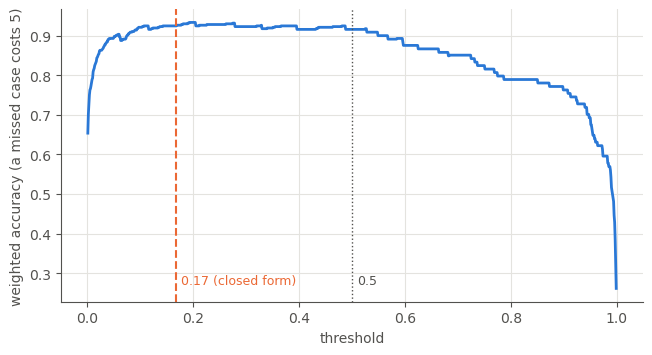

the sweep's best weighted accuracy: 0.9332 for thresholds 0.193 to 0.204


,threshold 0.5,closed form (0.167)
weighted accuracy,0.916,0.924
malignant cases missed,9.000,4.000
false alarms,3.000,23.000
recall,0.958,0.981
specificity,0.992,0.936


In [9]:
curves["weighted_accuracy"] = [at(t).compute("weighted_accuracy", "micro") for t in thresholds]
best, lo, hi = best_range(curves["weighted_accuracy"])
closed = wa.bayes_threshold()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(thresholds, curves["weighted_accuracy"], color=BLUE)
ax.axvline(0.5, color=INK2, linewidth=1, linestyle=":")
ax.axvline(closed, color=ORANGE, linewidth=1.5, linestyle="--")
ax.text(0.51, curves["weighted_accuracy"].min() + 0.01, "0.5", color=INK2, fontsize=9)
ax.text(closed + 0.01, curves["weighted_accuracy"].min() + 0.01, f"{closed:.2f} (closed form)", color=ORANGE, fontsize=9)
ax.set_xlabel("threshold")
ax.set_ylabel("weighted accuracy (a missed case costs 5)")
plt.show()

rows = {}
for label, t in (("threshold 0.5", 0.5), (f"closed form ({closed:.3f})", closed)):
    m = at(t)
    tp, fp, fn, tn = m.counts
    rows[label] = {"weighted accuracy": m.compute("weighted_accuracy", "micro"),
                   "malignant cases missed": int(fn), "false alarms": int(fp),
                   "recall": m.compute("recall", "micro"), "specificity": m.compute("specificity", "micro")}
print("the sweep's best weighted accuracy:", round(best, 4), "for thresholds", f"{lo:.3f} to {hi:.3f}")
pd.DataFrame(rows).round(3)

The closed form puts the threshold at $c_{FP}/(c_{FP}+c_{FN}) = 1/6$. It is the optimum for the *true*
conditional probabilities; the scores of a fitted model need not be calibrated, and here the sweep finds the
best weighted accuracy a little higher, between 0.19 and 0.20 (0.933 against 0.924). The curve is nearly flat
from about 0.1 to 0.5, so the score changes little, but what the errors are made of changes a lot: moving
from 0.5 to 1/6 cuts the missed malignant cases from 9 to 4 and raises the false alarms from 3 to 23, as
the cost asks. The same idea works for any cost ratio, and is the binary case of choosing, from
probabilities, the prediction with the minimum expected cost, as in notebook 04.

## What to report

- **Do not tune a threshold on recall, specificity or precision alone.** Each has a trivial maximiser; the
  first two are flagged by `diagnose` (`degenerate_optimum`), precision is not, and it behaves the same way.
- Use a measure that looks at both kinds of error ($F_1$, MCC, balanced accuracy), and check how flat the
  optimum is: here the curves are broad plateaus, so several thresholds are about equally good.
- When the **costs** are known, derive the threshold from them instead of searching: `register_measure` gives
  the closed form for a cost-weighted accuracy. It assumes calibrated probabilities, so check it against a
  sweep on held-out predictions.
- Choose the threshold on out-of-fold or held-out predictions, never on the data the model was trained on.

Next: soft labels and custom measures.